In [14]:
!sudo apt-get update -qq
!sudo apt-get install -y libopencv-dev pkg-config


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  at-spi2-common at-spi2-core gsettings-desktop-schemas
  gstreamer1.0-plugins-base libatk-bridge2.0-0t64 libatk1.0-0t64
  libatspi2.0-0t64 libavcodec-dev libavformat-dev libavutil-dev libcdparanoia0
  libcharls2 libdc1394-dev libdouble-conversion3 libevdev2 libexif-dev
  libexif-doc libexif12 libgdcm-dev libgdcm3.0t64 libgl2ps1.4 libglew2.2
  libgphoto2-6t64 libgphoto2-dev libgphoto2-l10n libgphoto2-port12t64
  libgstreamer-plugins-base1.0-0 libgtk-3-0t64 libgtk-3-bin libgtk-3-common
  libgudev-1.0-0 libimath-3-1-29t64 libimath-dev libinput-bin libinput10
  libmd4c0 libmtdev1t64 libopencv-calib3d-dev libopencv-calib3d406t64
  libopencv-contrib-dev libo

In [10]:
from pathlib import Path
import shutil

for nom in ["scene1.row3.col1.ppm", "scene1.row3.col3.ppm"]:
    fichiers = list(Path("/content").rglob(nom))

    if fichiers:
        destination = Path("/content") / nom
        if fichiers[0] != destination:
            shutil.copy2(fichiers[0], destination)
        print("OK :", destination)
    else:
        print("MANQUANT :", nom)

OK : /content/scene1.row3.col1.ppm
OK : /content/scene1.row3.col3.ppm


In [11]:
%%writefile /content/soru1.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <string>

using namespace cv;
using namespace std;

void kaydet(const Mat& disp16, string isim, int maxDisp) {
    Mat valid = disp16 > -16;

    Mat dispFloat;
    disp16.convertTo(dispFloat, CV_32F, 1.0 / 16.0);

    Mat gri = Mat::zeros(disp16.size(), CV_8UC1);

    for (int y = 0; y < disp16.rows; y++) {
        for (int x = 0; x < disp16.cols; x++) {
            if (valid.at<uchar>(y,x) != 0) {
                float d = dispFloat.at<float>(y,x);
                gri.at<uchar>(y,x) = saturate_cast<uchar>(
                    255.0 * d / (maxDisp - 1)
                );
            }
        }
    }

    Mat renkli;
    applyColorMap(gri, renkli, COLORMAP_JET);

    // Yalnizca gecersiz pikseller gri gosterilir
    renkli.setTo(Scalar(60,60,60), ~valid);

    // Gri haritada da gecersizleri ayirt et
    gri.setTo(0, ~valid);

    imwrite("/content/" + isim + "_gray.png", gri);
    imwrite("/content/" + isim + "_color.png", renkli);
    imwrite("/content/" + isim + "_valid.png", valid);

    int toplam = disp16.rows * disp16.cols;
    int gecerli = countNonZero(valid);

    cout << isim << endl;
    cout << "Gecerli piksel: " << gecerli << endl;
    cout << "Gecerli oran: "
         << 100.0 * gecerli / toplam << "%" << endl;
}

int main() {
    Mat sol = imread("/content/scene1.row3.col1.ppm");
    Mat sag = imread("/content/scene1.row3.col3.ppm");

    if (sol.empty() || sag.empty()) {
        cout << "HATA: Resimler bulunamadi!" << endl;
        return 1;
    }

    if (sol.size() != sag.size()) {
        cout << "HATA: Goruntu boyutlari farkli!" << endl;
        return 1;
    }

    Mat griSol, griSag;
    cvtColor(sol, griSol, COLOR_BGR2GRAY);
    cvtColor(sag, griSag, COLOR_BGR2GRAY);

    int maxDisp = 64;
    int blok = 9;

    Ptr<StereoBM> bm = StereoBM::create(maxDisp, blok);
    bm->setTextureThreshold(5);
    bm->setUniquenessRatio(5);

    Ptr<StereoSGBM> sgbm = StereoSGBM::create(
        0, maxDisp, 5,
        8 * 5 * 5,
        32 * 5 * 5,
        1, 31, 5, 0, 0,
        StereoSGBM::MODE_SGBM
    );

    Mat dispBM, dispSGBM;

    bm->compute(griSol, griSag, dispBM);
    sgbm->compute(griSol, griSag, dispSGBM);

    imwrite("/content/soru1_sol.png", sol);
    imwrite("/content/soru1_sag.png", sag);

    kaydet(dispBM, "soru1_StereoBM", maxDisp);
    kaydet(dispSGBM, "soru1_StereoSGBM", maxDisp);

    cout << "Islem tamamlandi!" << endl;

    return 0;
}

Writing /content/soru1.cpp


In [15]:
!g++ -std=c++17 -O2 /content/soru1.cpp -o /content/soru1 $(pkg-config --cflags --libs opencv4) && /content/soru1

soru1_StereoBM
Gecerli piksel: 79911
Gecerli oran: 72.2575%
soru1_StereoSGBM
Gecerli piksel: 88659
Gecerli oran: 80.1676%
Islem tamamlandi!


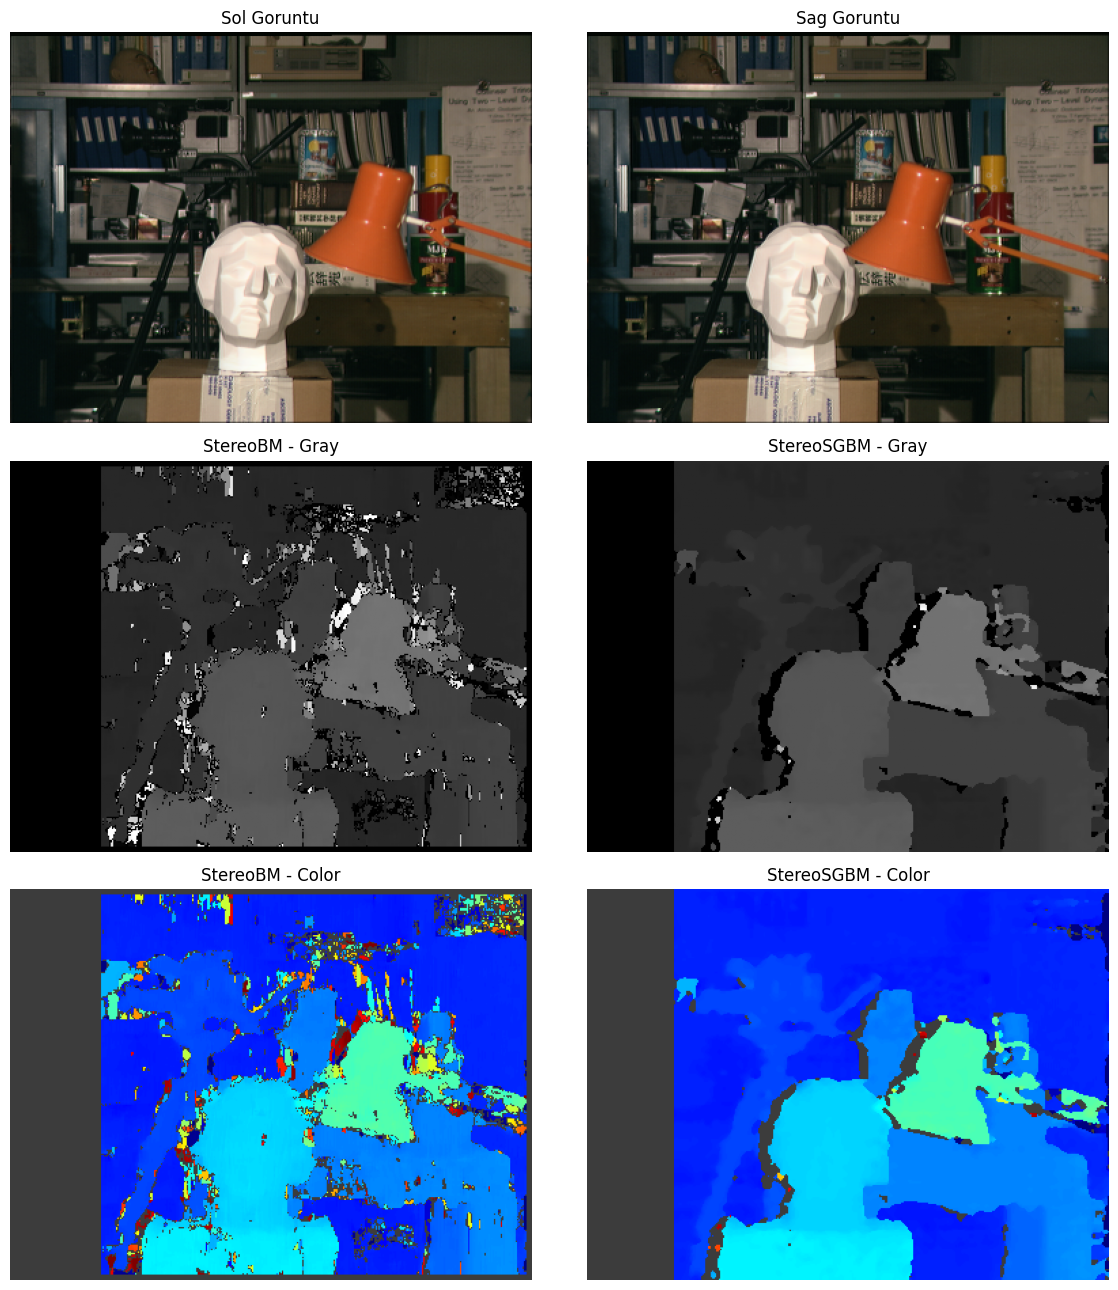

In [16]:
import cv2
import matplotlib.pyplot as plt

images = [
    ("soru1_sol.png", "Sol Goruntu"),
    ("soru1_sag.png", "Sag Goruntu"),
    ("soru1_StereoBM_gray.png", "StereoBM - Gray"),
    ("soru1_StereoSGBM_gray.png", "StereoSGBM - Gray"),
    ("soru1_StereoBM_color.png", "StereoBM - Color"),
    ("soru1_StereoSGBM_color.png", "StereoSGBM - Color")
]

fig, axes = plt.subplots(3, 2, figsize=(12, 13))

for ax, (nom, titre) in zip(axes.flat, images):
    img = cv2.imread("/content/" + nom, cv2.IMREAD_UNCHANGED)

    if img is None:
        print("Missing:", nom)
    elif img.ndim == 2:
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    else:
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

    ax.set_title(titre)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [17]:
%%writefile /content/soru2.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <cmath>
using namespace cv;
using namespace std;

const int BLOK = 7;
const int MAX_DISP = 64;

int SAD(const Mat& sol, const Mat& sag, int x, int xr, int y) {
    int toplam = 0;
    int r = BLOK / 2;

    for (int j = -r; j <= r; j++) {
        for (int i = -r; i <= r; i++) {
            int a = sol.at<uchar>(y+j, x+i);
            int b = sag.at<uchar>(y+j, xr+i);

            toplam += abs(a-b);
        }
    }

    return toplam;
}

Mat blokEslestirme(const Mat& sol, const Mat& sag) {
    Mat disparite(sol.size(), CV_16SC1, Scalar(-1));
    int r = BLOK / 2;

    for (int y = r; y < sol.rows-r; y++) {
        for (int x = r; x < sol.cols-r; x++) {

            int enDusuk = 1000000000;
            int enIyiD = -1;

            for (int d = 0; d < MAX_DISP; d++) {
                int xr = x-d;

                if (xr-r < 0)
                    break;

                int puan = SAD(sol, sag, x, xr, y);

                if (puan < enDusuk) {
                    enDusuk = puan;
                    enIyiD = d;
                }
            }

            if (enIyiD >= 0)
                disparite.at<short>(y,x) = enIyiD;
        }
    }

    return disparite;
}

void kaydet(const Mat& disparite) {
    Mat gri(disparite.size(), CV_8UC1, Scalar(0));
    Mat maske = disparite >= 0;

    for (int y = 0; y < disparite.rows; y++) {
        for (int x = 0; x < disparite.cols; x++) {

            int d = disparite.at<short>(y,x);

            if (d >= 0) {
                gri.at<uchar>(y,x) =
                    saturate_cast<uchar>(
                        255.0 * d / (MAX_DISP-1)
                    );
            }
        }
    }

    Mat renkli;
    applyColorMap(gri, renkli, COLORMAP_JET);

    // Sadece gecersiz pikseller gri
    renkli.setTo(Scalar(60,60,60), ~maske);

    imwrite("/content/soru2_manual_gray.png", gri);
    imwrite("/content/soru2_manual_color.png", renkli);
    imwrite("/content/soru2_manual_valid.png", maske);

    int toplam = disparite.rows * disparite.cols;
    int gecerli = countNonZero(maske);

    cout << "Gecerli piksel: " << gecerli << endl;
    cout << "Gecerli oran: "
         << 100.0 * gecerli / toplam << "%" << endl;
}

int main() {
    Mat sol = imread("/content/scene1.row3.col1.ppm");
    Mat sag = imread("/content/scene1.row3.col3.ppm");

    if (sol.empty() || sag.empty()) {
        cout << "HATA: Resimler bulunamadi!" << endl;
        return 1;
    }

    if (sol.size() != sag.size()) {
        cout << "HATA: Resim boyutlari farkli!" << endl;
        return 1;
    }

    Mat griSol, griSag;
    cvtColor(sol, griSol, COLOR_BGR2GRAY);
    cvtColor(sag, griSag, COLOR_BGR2GRAY);

    cout << "Blok eslestirme basladi..." << endl;

    Mat disparite = blokEslestirme(griSol, griSag);

    kaydet(disparite);

    imwrite("/content/soru2_sol.png", sol);
    imwrite("/content/soru2_sag.png", sag);

    cout << "Islem tamamlandi!" << endl;

    return 0;
}

Writing /content/soru2.cpp


In [18]:
!g++ -std=c++17 -O2 /content/soru2.cpp -o /content/soru2 $(pkg-config --cflags --libs opencv4) && /content/soru2

Blok eslestirme basladi...
Gecerli piksel: 106596
Gecerli oran: 96.3867%
Islem tamamlandi!


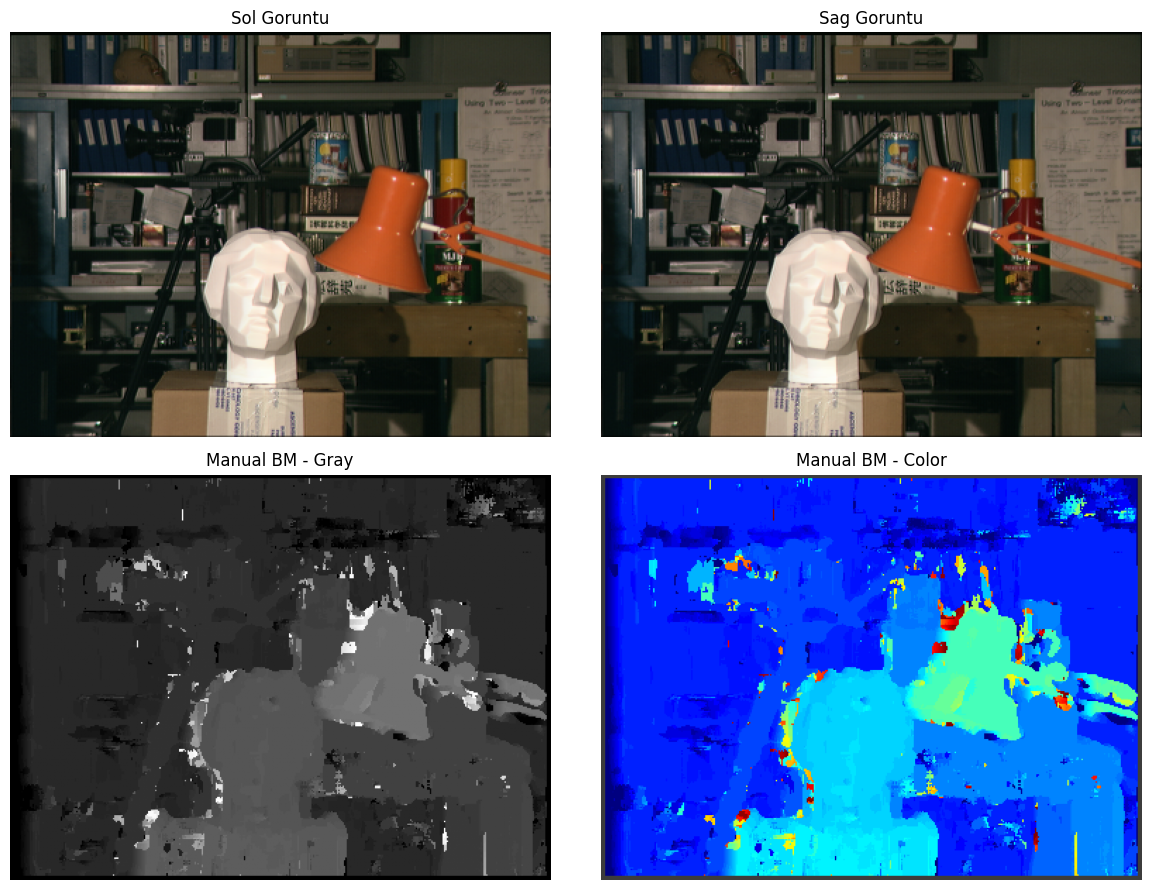

In [19]:
import cv2
import matplotlib.pyplot as plt

images = [
    ("soru2_sol.png", "Sol Goruntu"),
    ("soru2_sag.png", "Sag Goruntu"),
    ("soru2_manual_gray.png", "Manual BM - Gray"),
    ("soru2_manual_color.png", "Manual BM - Color")
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (nom, titre) in zip(axes.flat, images):
    img = cv2.imread("/content/" + nom, cv2.IMREAD_UNCHANGED)

    if img is None:
        print("Missing:", nom)
    elif img.ndim == 2:
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    else:
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

    ax.set_title(titre)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [24]:
%%writefile /content/soru3.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <cmath>
#include <chrono>

using namespace cv;
using namespace std;

const int BLOK = 7;
const int MAX_DISP = 64;

using Benzerlik = double (*)(const Mat&, const Mat&);

double SAD(const Mat& a, const Mat& b) {
    double toplam = 0;

    for (int y = 0; y < a.rows; y++) {
        for (int x = 0; x < a.cols; x++) {
            int fark = int(a.at<uchar>(y,x)) -
                       int(b.at<uchar>(y,x));
            toplam += abs(fark);
        }
    }
    return toplam;
}

double SSD(const Mat& a, const Mat& b) {
    double toplam = 0;

    for (int y = 0; y < a.rows; y++) {
        for (int x = 0; x < a.cols; x++) {
            double fark = double(a.at<uchar>(y,x)) -
                          double(b.at<uchar>(y,x));
            toplam += fark * fark;
        }
    }
    return toplam;
}

double ZNCC(const Mat& a, const Mat& b) {
    double ortA = mean(a)[0];
    double ortB = mean(b)[0];

    double ust = 0;
    double altA = 0;
    double altB = 0;

    for (int y = 0; y < a.rows; y++) {
        for (int x = 0; x < a.cols; x++) {
            double va = a.at<uchar>(y,x) - ortA;
            double vb = b.at<uchar>(y,x) - ortB;

            ust += va * vb;
            altA += va * va;
            altB += vb * vb;
        }
    }

    if (altA < 1e-9 || altB < 1e-9)
        return -2.0;

    return ust / sqrt(altA * altB);
}

Mat eslestir(const Mat& sol, const Mat& sag,
             Benzerlik fonksiyon, bool maksimum) {

    Mat sonuc(sol.size(), CV_16SC1, Scalar(-1));
    int r = BLOK / 2;

    for (int y = r; y < sol.rows-r; y++) {
        for (int x = r; x < sol.cols-r; x++) {

            Mat a = sol(Rect(x-r, y-r, BLOK, BLOK));

            double enIyi = maksimum ? -2.0 : 1e30;
            int enIyiD = -1;

            for (int d = 0; d < MAX_DISP; d++) {
                int xr = x-d;

                if (xr-r < 0)
                    break;

                Mat b = sag(Rect(xr-r, y-r, BLOK, BLOK));
                double puan = fonksiyon(a,b);

                if (maksimum && puan < -1.5)
                    continue;

                bool dahaIyi = maksimum
                    ? puan > enIyi
                    : puan < enIyi;

                if (enIyiD == -1 || dahaIyi) {
                    enIyi = puan;
                    enIyiD = d;
                }
            }

            if (enIyiD >= 0)
                sonuc.at<short>(y,x) = enIyiD;
        }
    }

    return sonuc;
}

void kaydet(const Mat& disp, string isim) {
    Mat gri(disp.size(), CV_8UC1, Scalar(0));
    Mat valid = disp >= 0;

    for (int y = 0; y < disp.rows; y++) {
        for (int x = 0; x < disp.cols; x++) {
            int d = disp.at<short>(y,x);

            if (d >= 0) {
                gri.at<uchar>(y,x) =
                    saturate_cast<uchar>(
                        255.0 * d / (MAX_DISP-1)
                    );
            }
        }
    }

    Mat renkli;
    applyColorMap(gri,renkli,COLORMAP_JET);

    // Sadece gecersiz pikseller gri
    renkli.setTo(Scalar(60,60,60),~valid);

    imwrite("/content/soru3_"+isim+"_gray.png",gri);
    imwrite("/content/soru3_"+isim+"_color.png",renkli);
    imwrite("/content/soru3_"+isim+"_valid.png",valid);

    cout << isim << " - Gecerli piksel: "
         << countNonZero(valid) << endl;
}

int main() {
    Mat sol = imread("/content/scene1.row3.col1.ppm");
    Mat sag = imread("/content/scene1.row3.col3.ppm");

    if (sol.empty() || sag.empty()) {
        cout << "HATA: Resimler bulunamadi!" << endl;
        return 1;
    }

    if (sol.size() != sag.size()) {
        cout << "HATA: Resim boyutlari farkli!" << endl;
        return 1;
    }

    Mat griSol, griSag;
    cvtColor(sol,griSol,COLOR_BGR2GRAY);
    cvtColor(sag,griSag,COLOR_BGR2GRAY);

    Benzerlik fonksiyonlar[3] = {SAD,SSD,ZNCC};
    string isimler[3] = {"SAD","SSD","ZNCC"};
    bool maksimum[3] = {false,false,true};

    Mat haritalar[3];

    for (int i = 0; i < 3; i++) {
        auto basla = chrono::steady_clock::now();

        haritalar[i] = eslestir(
            griSol,griSag,
            fonksiyonlar[i],
            maksimum[i]
        );

        auto bitir = chrono::steady_clock::now();

        double sure = chrono::duration<double>(
            bitir-basla
        ).count();

        cout << isimler[i]
             << " - Sure: " << sure
             << " saniye" << endl;

        kaydet(haritalar[i],isimler[i]);
    }

    Mat fark = Mat::zeros(sol.size(),CV_8UC1);

    for (int y = 0; y < sol.rows; y++) {
        for (int x = 0; x < sol.cols; x++) {
            int a = haritalar[0].at<short>(y,x);
            int b = haritalar[1].at<short>(y,x);

            if (a >= 0 && b >= 0) {
                fark.at<uchar>(y,x) =
                    saturate_cast<uchar>(
                        255.0 * abs(a-b) / (MAX_DISP-1)
                    );
            }
        }
    }

    imwrite("/content/soru3_SAD_SSD_fark.png",fark);

    cout << "Tum islemler tamamlandi!" << endl;
    return 0;
}

Writing /content/soru3.cpp


In [25]:
!g++ -std=c++17 -O2 /content/soru3.cpp -o /content/soru3 $(pkg-config --cflags --libs opencv4) && /content/soru3

SAD - Sure: 0.635232 saniye
SAD - Gecerli piksel: 106596
SSD - Sure: 0.608948 saniye
SSD - Gecerli piksel: 106596
ZNCC - Sure: 4.79648 saniye
ZNCC - Gecerli piksel: 106596
Tum islemler tamamlandi!


In [26]:
!sudo apt-get install -y libopencv-dev pkg-config

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
libopencv-dev is already the newest version (4.6.0+dfsg-13.1ubuntu1).
pkg-config is already the newest version (1.8.1-2build1).
0 upgraded, 0 newly installed, 0 to remove and 114 not upgraded.


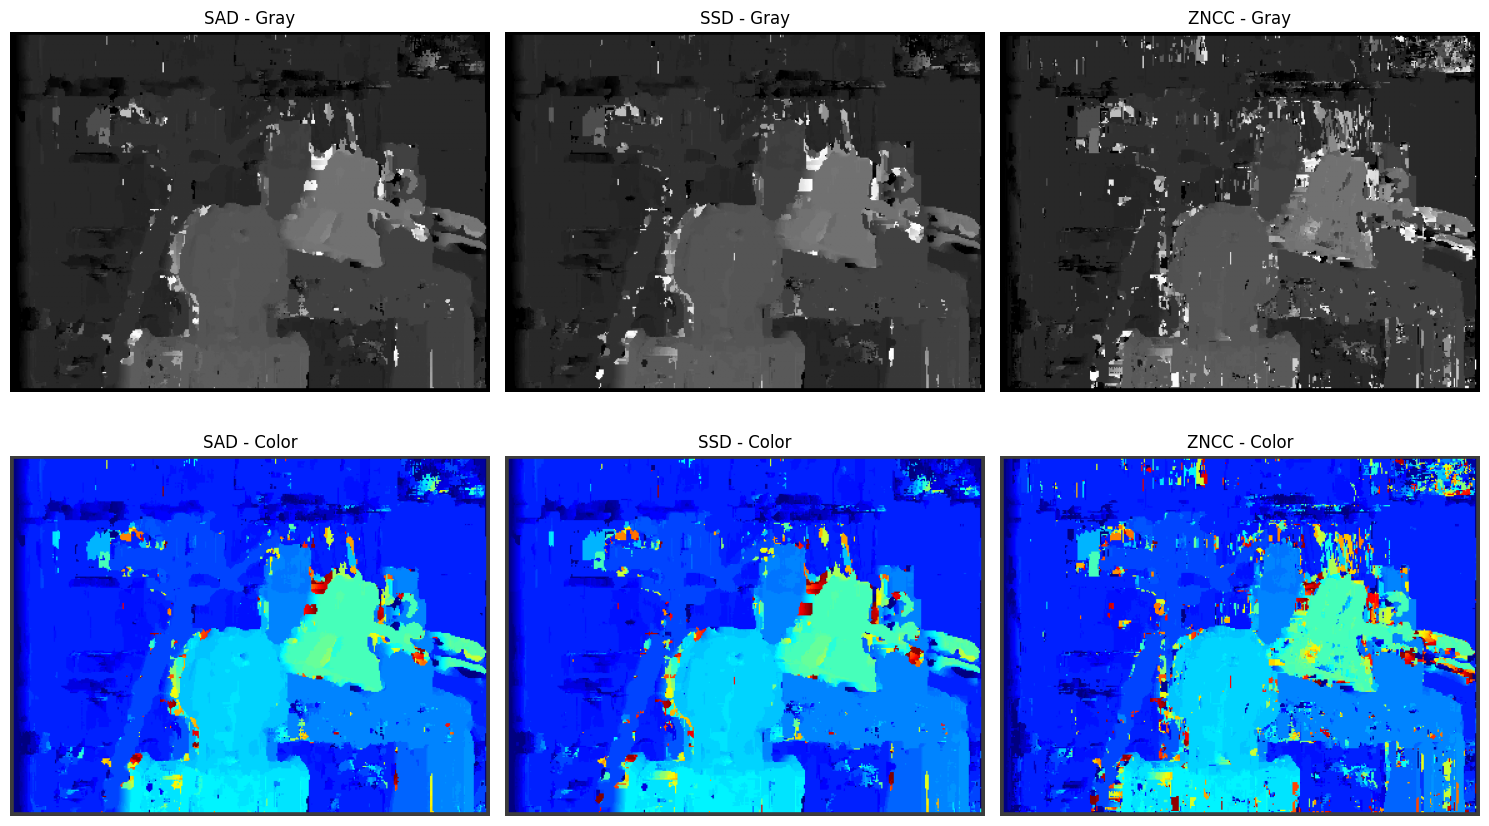

In [27]:
import cv2
import matplotlib.pyplot as plt

noms = ["SAD", "SSD", "ZNCC"]

fig, axes = plt.subplots(2,3,figsize=(15,9))

for i, nom in enumerate(noms):
    gray = cv2.imread(f"/content/soru3_{nom}_gray.png",0)
    color = cv2.imread(f"/content/soru3_{nom}_color.png")

    if gray is not None:
        axes[0,i].imshow(gray,cmap="gray",vmin=0,vmax=255)
    else:
        print("Manquant :",nom,"Gray")

    if color is not None:
        axes[1,i].imshow(cv2.cvtColor(color,cv2.COLOR_BGR2RGB))
    else:
        print("Manquant :",nom,"Color")

    axes[0,i].set_title(nom+" - Gray")
    axes[1,i].set_title(nom+" - Color")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

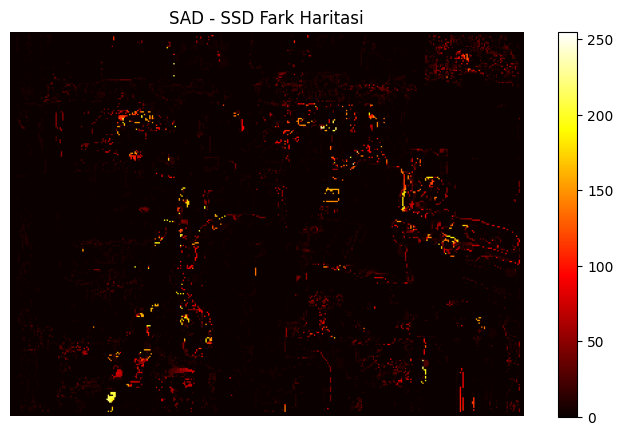

In [28]:
import cv2
import matplotlib.pyplot as plt

fark = cv2.imread("/content/soru3_SAD_SSD_fark.png",0)

if fark is not None:
    plt.figure(figsize=(9,5))
    plt.imshow(fark,cmap="hot",vmin=0,vmax=255)
    plt.title("SAD - SSD Fark Haritasi")
    plt.colorbar()
    plt.axis("off")
    plt.show()
else:
    print("Image introuvable.")

In [29]:
%%writefile /content/soru4.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <vector>
#include <algorithm>
#include <chrono>

using namespace cv;
using namespace std;

const int D = 48;
const int BLOK = 5;
const float INF = 1000000.0f;

int W, H;

int indeks(int x, int y, int d) {
    return (y * W + x) * D + d;
}

vector<float> maliyetHesapla(const Mat& sol, const Mat& sag) {
    vector<float> C(W * H * D, INF);
    int r = BLOK / 2;

    for (int y = r; y < H-r; y++) {
        for (int x = r; x < W-r; x++) {
            Mat a = sol(Rect(x-r, y-r, BLOK, BLOK));

            for (int d = 0; d < D; d++) {
                if (x-d-r < 0) break;

                Mat b = sag(Rect(x-d-r, y-r, BLOK, BLOK));

                Mat fark;
                absdiff(a, b, fark);

                C[indeks(x,y,d)] =
                    sum(fark)[0] / (BLOK * BLOK);
            }
        }
    }
    return C;
}

void yolHesapla(const vector<float>& C,
                vector<float>& S,
                int x, int y, int dx, int dy,
                float P1, float P2) {

    vector<float> onceki(D, 0);
    vector<float> simdiki(D, 0);

    bool ilk = true;

    while (x >= 0 && x < W && y >= 0 && y < H) {
        float minimum = 0;

        if (!ilk) {
            minimum = *min_element(
                onceki.begin(), onceki.end()
            );
        }

        for (int d = 0; d < D; d++) {
            int k = indeks(x,y,d);

            if (ilk) {
                simdiki[d] = C[k];
            } else {
                float a = onceki[d];

                float b = d > 0
                    ? onceki[d-1] + P1 : INF;

                float c = d < D-1
                    ? onceki[d+1] + P1 : INF;

                float e = minimum + P2;

                float enDusuk = min(min(a,b), min(c,e));

                simdiki[d] =
                    C[k] + enDusuk - minimum;
            }

            S[k] += simdiki[d];
        }

        onceki.swap(simdiki);
        ilk = false;

        x += dx;
        y += dy;
    }
}

Mat SGM(const vector<float>& C, float P1, float P2) {
    vector<float> S(W * H * D, 0);
    int r = BLOK / 2;

    for (int y = r; y < H-r; y++) {
        yolHesapla(C, S, r, y, 1, 0, P1, P2);
        yolHesapla(C, S, W-r-1, y, -1, 0, P1, P2);
    }

    for (int x = r; x < W-r; x++) {
        yolHesapla(C, S, x, r, 0, 1, P1, P2);
        yolHesapla(C, S, x, H-r-1, 0, -1, P1, P2);
    }

    Mat disp(H, W, CV_16SC1, Scalar(-1));

    for (int y = r; y < H-r; y++) {
        for (int x = r; x < W-r; x++) {
            float enDusuk = INF * 10;
            int enIyiD = -1;

            for (int d = 0; d < D; d++) {
                int k = indeks(x,y,d);

                if (C[k] >= INF)
                    continue;

                if (S[k] < enDusuk) {
                    enDusuk = S[k];
                    enIyiD = d;
                }
            }

            if (enIyiD >= 0)
                disp.at<short>(y,x) = enIyiD;
        }
    }

    return disp;
}

void kaydet(const Mat& disp, string isim) {
    Mat gri(disp.size(), CV_8UC1, Scalar(0));
    Mat valid = disp >= 0;

    for (int y = 0; y < disp.rows; y++) {
        for (int x = 0; x < disp.cols; x++) {
            int d = disp.at<short>(y,x);

            if (d >= 0) {
                gri.at<uchar>(y,x) =
                    saturate_cast<uchar>(
                        12.0 + 243.0 * d / (D-1)
                    );
            }
        }
    }

    Mat renkli;
    applyColorMap(gri, renkli, COLORMAP_JET);

    renkli.setTo(Scalar(65,65,65), ~valid);

    imwrite("/content/" + isim + "_gray.png", gri);
    imwrite("/content/" + isim + "_color.png", renkli);
    imwrite("/content/" + isim + "_valid.png", valid);

    cout << isim << " - Gecerli piksel: "
         << countNonZero(valid) << endl;
}

int main() {
    Mat sol = imread("/content/scene1.row3.col1.ppm");
    Mat sag = imread("/content/scene1.row3.col3.ppm");

    if (sol.empty() || sag.empty()) {
        cout << "HATA: Stereo resimleri bulunamadi!" << endl;
        return 1;
    }

    if (sol.size() != sag.size()) {
        cout << "HATA: Boyutlar farkli!" << endl;
        return 1;
    }

    W = min(256, sol.cols);
    H = max(1, cvRound(sol.rows * double(W) / sol.cols));

    if (W < D+BLOK || H < BLOK) {
        cout << "HATA: Resimler cok kucuk!" << endl;
        return 1;
    }

    resize(sol, sol, Size(W,H));
    resize(sag, sag, Size(W,H));

    Mat griSol, griSag;
    cvtColor(sol, griSol, COLOR_BGR2GRAY);
    cvtColor(sag, griSag, COLOR_BGR2GRAY);

    auto basla = chrono::steady_clock::now();

    vector<float> C = maliyetHesapla(griSol, griSag);

    Mat az = SGM(C, 3, 12);
    Mat cok = SGM(C, 15, 60);

    auto bitir = chrono::steady_clock::now();

    kaydet(az, "soru4_smoothness_az");
    kaydet(cok, "soru4_smoothness_cok");

    Mat fark(H, W, CV_8UC1, Scalar(0));

    for (int y = 0; y < H; y++) {
        for (int x = 0; x < W; x++) {
            int a = az.at<short>(y,x);
            int b = cok.at<short>(y,x);

            if (a >= 0 && b >= 0) {
                fark.at<uchar>(y,x) =
                    saturate_cast<uchar>(
                        255.0 * abs(a-b) / (D-1)
                    );
            }
        }
    }

    imwrite("/content/soru4_smoothness_fark.png", fark);

    double sure = chrono::duration<double>(
        bitir-basla
    ).count();

    cout << "Sure: " << sure << " saniye" << endl;
    cout << "Farkli piksel: " << countNonZero(fark) << endl;
    cout << "SGM islemi tamamlandi!" << endl;

    return 0;
}

Writing /content/soru4.cpp


In [30]:
!g++ -std=c++17 -O2 /content/soru4.cpp -o /content/soru4 $(pkg-config --cflags --libs opencv4) && /content/soru4

soru4_smoothness_az - Gecerli piksel: 47376
soru4_smoothness_cok - Gecerli piksel: 47376
Sure: 1.13825 saniye
Farkli piksel: 7104
SGM islemi tamamlandi!


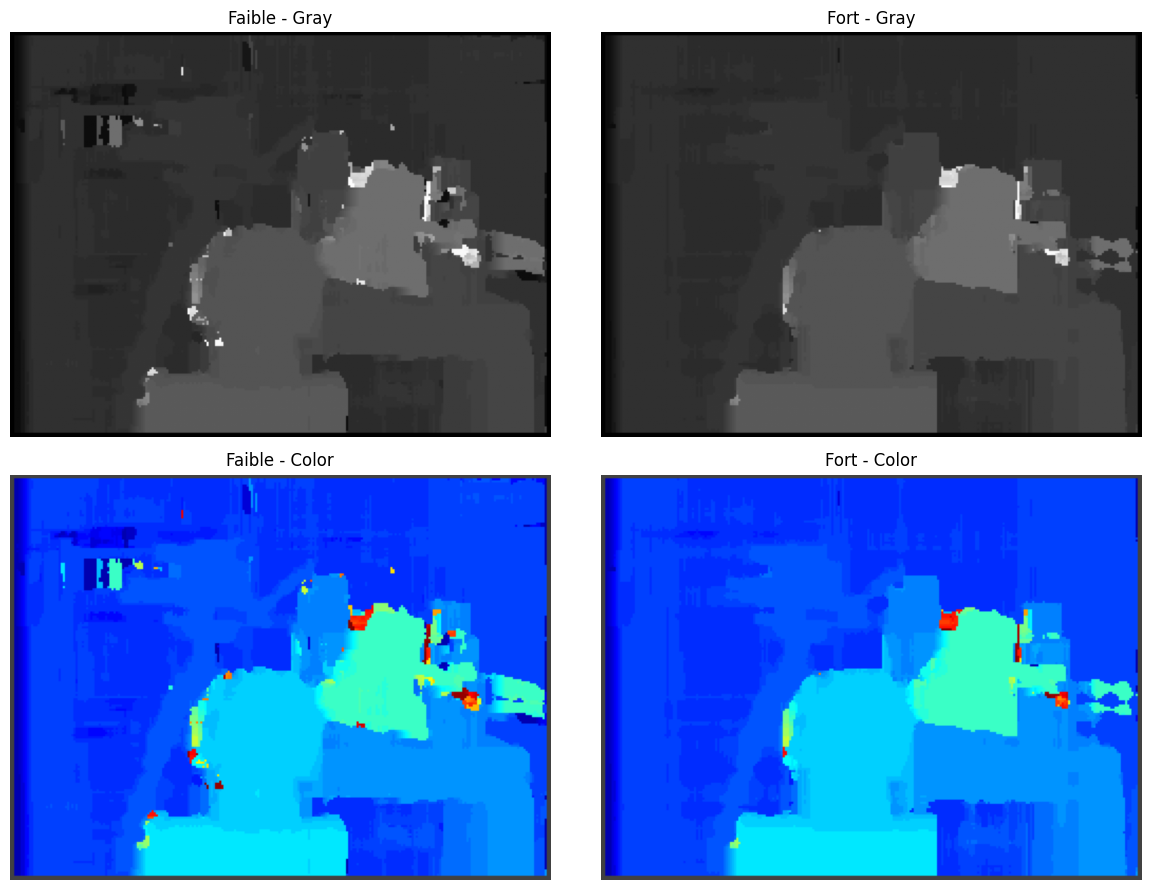

In [31]:
import cv2
import matplotlib.pyplot as plt

images = [
    ("soru4_smoothness_az_gray.png", "Faible - Gray"),
    ("soru4_smoothness_cok_gray.png", "Fort - Gray"),
    ("soru4_smoothness_az_color.png", "Faible - Color"),
    ("soru4_smoothness_cok_color.png", "Fort - Color")
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (nom, titre) in zip(axes.flat, images):
    img = cv2.imread("/content/" + nom, cv2.IMREAD_UNCHANGED)

    if img is None:
        print("Manquant :", nom)
    elif img.ndim == 2:
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    else:
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

    ax.set_title(titre)
    ax.axis("off")

plt.tight_layout()
plt.show()

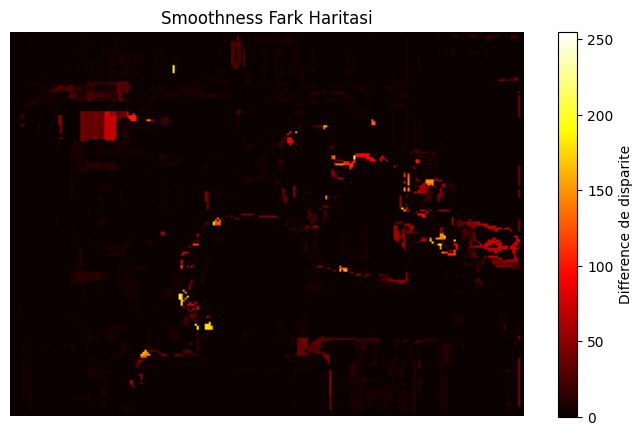

In [32]:
import cv2
import matplotlib.pyplot as plt

fark = cv2.imread(
    "/content/soru4_smoothness_fark.png", 0
)

if fark is not None:
    plt.figure(figsize=(9, 5))
    plt.imshow(fark, cmap="hot", vmin=0, vmax=255)
    plt.title("Smoothness Fark Haritasi")
    plt.colorbar(label="Difference de disparite")
    plt.axis("off")
    plt.show()
else:
    print("Image introuvable.")

In [33]:
!pkg-config --modversion opencv4
!ls /content/scene1.row3.col1.ppm /content/scene1.row3.col3.ppm

4.6.0
/content/scene1.row3.col1.ppm  /content/scene1.row3.col3.ppm


In [34]:
!sudo apt-get update -qq
!sudo apt-get install -y libopencv-dev pkg-config

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
libopencv-dev is already the newest version (4.6.0+dfsg-13.1ubuntu1).
pkg-config is already the newest version (1.8.1-2build1).
0 upgraded, 0 newly installed, 0 to remove and 114 not upgraded.


In [35]:
%%writefile /content/ev_odevi.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <chrono>
#include <cmath>
#include <climits>
using namespace cv;
using namespace std;

const int BLOK = 5;
const int MAX_DISP = 32;

double SAD(const Mat& a, const Mat& b,
           int x1, int x2, int y) {
    double toplam = 0;
    int r = BLOK / 2;

    for (int j = -r; j <= r; j++) {
        for (int i = -r; i <= r; i++) {
            int sol = a.at<uchar>(y+j,x1+i);
            int sag = b.at<uchar>(y+j,x2+i);
            toplam += abs(sol-sag);
        }
    }
    return toplam;
}

Mat eslestir(const Mat& sol, const Mat& sag,
             const Mat& kenarSol, const Mat& kenarSag,
             bool sparse, bool ters) {

    Mat disp(sol.size(), CV_16SC1, Scalar(-1));
    Mat genisKenar;

    if (sparse) {
        Mat eleman = getStructuringElement(
            MORPH_RECT, Size(3,1)
        );
        dilate(kenarSag, genisKenar, eleman);
    }

    int r = BLOK / 2;

    for (int y = r; y < sol.rows-r; y++) {
        for (int x = r; x < sol.cols-r; x++) {

            if (sparse && kenarSol.at<uchar>(y,x) == 0)
                continue;

            double enDusuk = 1e30;
            int enIyiD = -1;

            for (int d = 0; d < MAX_DISP; d++) {
                int xr = ters ? x+d : x-d;

                if (xr-r < 0 || xr+r >= sag.cols)
                    break;

                if (sparse &&
                    genisKenar.at<uchar>(y,xr) == 0)
                    continue;

                double puan = SAD(sol,sag,x,xr,y);

                if (puan < enDusuk) {
                    enDusuk = puan;
                    enIyiD = d;
                }
            }

            if (enIyiD >= 0)
                disp.at<short>(y,x) = enIyiD;
        }
    }

    return disp;
}

void kaydet(const Mat& disp, string isim) {
    Mat gri(disp.size(), CV_8UC1, Scalar(0));
    Mat valid = disp >= 0;

    for (int y = 0; y < disp.rows; y++) {
        for (int x = 0; x < disp.cols; x++) {
            int d = disp.at<short>(y,x);

            if (d >= 0) {
                gri.at<uchar>(y,x) =
                    saturate_cast<uchar>(
                        20.0 + 235.0*d/(MAX_DISP-1)
                    );
            }
        }
    }

    Mat renkli;
    applyColorMap(gri,renkli,COLORMAP_JET);

    // Gecersiz pikseller siyah yerine gri
    renkli.setTo(Scalar(65,65,65),~valid);

    imwrite("/content/"+isim+"_gray.png",gri);
    imwrite("/content/"+isim+"_color.png",renkli);
    imwrite("/content/"+isim+"_valid.png",valid);
}

double tutarlilik(const Mat& solDisp,
                  const Mat& sagDisp,
                  const Mat& kenar,
                  int& kontrol) {

    int uygun = 0;
    kontrol = 0;

    for (int y = 0; y < solDisp.rows; y++) {
        for (int x = 0; x < solDisp.cols; x++) {

            // Iki yontemi ayni sol kenarlarda karsilastir
            if (kenar.at<uchar>(y,x) == 0)
                continue;

            int d = solDisp.at<short>(y,x);
            if (d < 0)
                continue;

            int xr = x-d;

            if (xr < 0 || xr >= sagDisp.cols)
                continue;

            int dr = sagDisp.at<short>(y,xr);

            if (dr < 0)
                continue;

            kontrol++;

            if (abs(d-dr) <= 1)
                uygun++;
        }
    }

    if (kontrol == 0)
        return 0;

    return 100.0*uygun/kontrol;
}

int main() {
    Mat sol = imread("/content/scene1.row3.col1.ppm");
    Mat sag = imread("/content/scene1.row3.col3.ppm");

    if (sol.empty() || sag.empty()) {
        cout << "HATA: Resimler bulunamadi!" << endl;
        return 1;
    }

    if (sol.size() != sag.size()) {
        cout << "HATA: Boyutlar farkli!" << endl;
        return 1;
    }

    int w = min(240,sol.cols);
    int h = max(1,cvRound(
        sol.rows*double(w)/sol.cols
    ));

    if (w < MAX_DISP+BLOK || h < BLOK) {
        cout << "HATA: Resimler cok kucuk!" << endl;
        return 1;
    }

    resize(sol,sol,Size(w,h));
    resize(sag,sag,Size(w,h));

    Mat griSol,griSag;
    cvtColor(sol,griSol,COLOR_BGR2GRAY);
    cvtColor(sag,griSag,COLOR_BGR2GRAY);

    imwrite("/content/ev_sol.png",sol);
    imwrite("/content/ev_sag.png",sag);

    // 1 - Kenar tespiti
    auto t0 = chrono::steady_clock::now();

    Mat kenarSol,kenarSag;
    Canny(griSol,kenarSol,60,140);
    Canny(griSag,kenarSag,60,140);

    auto t1 = chrono::steady_clock::now();

    imwrite("/content/ev_kenar_sol.png",kenarSol);
    imwrite("/content/ev_kenar_sag.png",kenarSag);

    // 2 - Sparse Stereo
    auto t2 = chrono::steady_clock::now();

    Mat sparse = eslestir(
        griSol,griSag,kenarSol,kenarSag,true,false
    );

    auto t3 = chrono::steady_clock::now();

    // 3 - Dense Stereo
    auto t4 = chrono::steady_clock::now();

    Mat dense = eslestir(
        griSol,griSag,kenarSol,kenarSag,false,false
    );

    auto t5 = chrono::steady_clock::now();

    // Ters yone eslestirme: tutarlilik kontrolu
    Mat sparseGeri = eslestir(
        griSag,griSol,kenarSag,kenarSol,true,true
    );

    Mat denseGeri = eslestir(
        griSag,griSol,kenarSag,kenarSol,false,true
    );

    kaydet(sparse,"ev_sparse");
    kaydet(dense,"ev_dense");

    double sureKenar =
        chrono::duration<double>(t1-t0).count();

    double sureSparse =
        chrono::duration<double>(t3-t2).count();

    double sureDense =
        chrono::duration<double>(t5-t4).count();

    int kontrolSparse = 0;
    int kontrolDense = 0;

    double kaliteSparse = tutarlilik(
        sparse,sparseGeri,kenarSol,kontrolSparse
    );

    double kaliteDense = tutarlilik(
        dense,denseGeri,kenarSol,kontrolDense
    );

    int kenarSayisi = countNonZero(kenarSol);
    int sparseSayisi = countNonZero(sparse >= 0);
    int denseSayisi = countNonZero(dense >= 0);
    int toplam = w*h;

    cout << "\n=== EV ODEVI SONUCLARI ===" << endl;

    cout << "\nKENAR TESPITI" << endl;
    cout << "Kenar pikseli: " << kenarSayisi << endl;
    cout << "Sure: " << sureKenar << " saniye" << endl;

    cout << "\nSPARSE STEREO" << endl;
    cout << "Eslesme suresi: "
         << sureSparse << " saniye" << endl;
    cout << "Toplam sure (Canny dahil): "
         << sureSparse+sureKenar << " saniye" << endl;
    cout << "Gecerli piksel: " << sparseSayisi << endl;
    cout << "Kapsama: "
         << 100.0*sparseSayisi/toplam << "%" << endl;
    cout << "Sol-sag tutarlilik: "
         << kaliteSparse << "%" << endl;
    cout << "Kontrol edilen: " << kontrolSparse << endl;

    cout << "\nDENSE STEREO" << endl;
    cout << "Eslesme suresi: "
         << sureDense << " saniye" << endl;
    cout << "Gecerli piksel: " << denseSayisi << endl;
    cout << "Kapsama: "
         << 100.0*denseSayisi/toplam << "%" << endl;
    cout << "Sol-sag tutarlilik (kenarlarda): "
         << kaliteDense << "%" << endl;
    cout << "Kontrol edilen: " << kontrolDense << endl;

    cout << "\nNOT: Tutarlilik gercek dogruluk degildir."
         << endl;

    cout << "Islem tamamlandi!" << endl;
    return 0;
}

Writing /content/ev_odevi.cpp


In [36]:
!g++ -std=c++17 -O2 /content/ev_odevi.cpp -o /content/ev_odevi $(pkg-config --cflags --libs opencv4) && /content/ev_odevi


=== EV ODEVI SONUCLARI ===

KENAR TESPITI
Kenar pikseli: 7737
Sure: 0.00334456 saniye

SPARSE STEREO
Eslesme suresi: 0.00992724 saniye
Toplam sure (Canny dahil): 0.0132718 saniye
Gecerli piksel: 7102
Kapsama: 16.4398%
Sol-sag tutarlilik: 90.4085%
Kontrol edilen: 5484

DENSE STEREO
Eslesme suresi: 0.0823232 saniye
Gecerli piksel: 41536
Kapsama: 96.1481%
Sol-sag tutarlilik (kenarlarda): 88.8162%
Kontrol edilen: 7180

NOT: Tutarlilik gercek dogruluk degildir.
Islem tamamlandi!


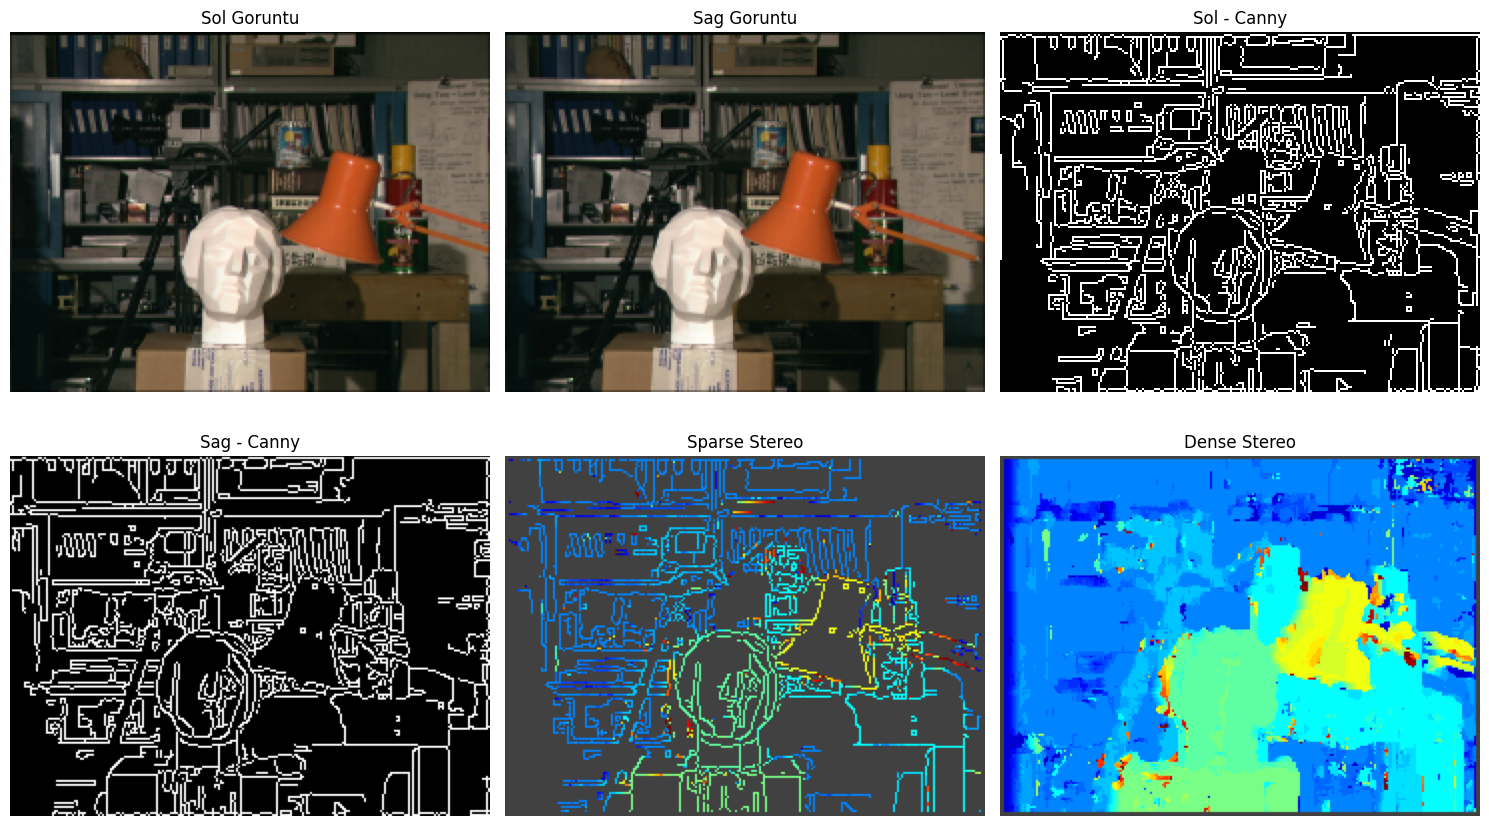

In [37]:
import cv2
import matplotlib.pyplot as plt

images = [
    ("ev_sol.png", "Sol Goruntu"),
    ("ev_sag.png", "Sag Goruntu"),
    ("ev_kenar_sol.png", "Sol - Canny"),
    ("ev_kenar_sag.png", "Sag - Canny"),
    ("ev_sparse_color.png", "Sparse Stereo"),
    ("ev_dense_color.png", "Dense Stereo")
]

fig, axes = plt.subplots(2,3,figsize=(15,9))

for ax, (nom,titre) in zip(axes.flat,images):
    img = cv2.imread("/content/"+nom,cv2.IMREAD_UNCHANGED)

    if img is None:
        print("Manquant :",nom)
    elif img.ndim == 2:
        ax.imshow(img,cmap="gray",vmin=0,vmax=255)
    else:
        ax.imshow(cv2.cvtColor(img,cv2.COLOR_BGR2RGB))

    ax.set_title(titre)
    ax.axis("off")

plt.tight_layout()
plt.show()

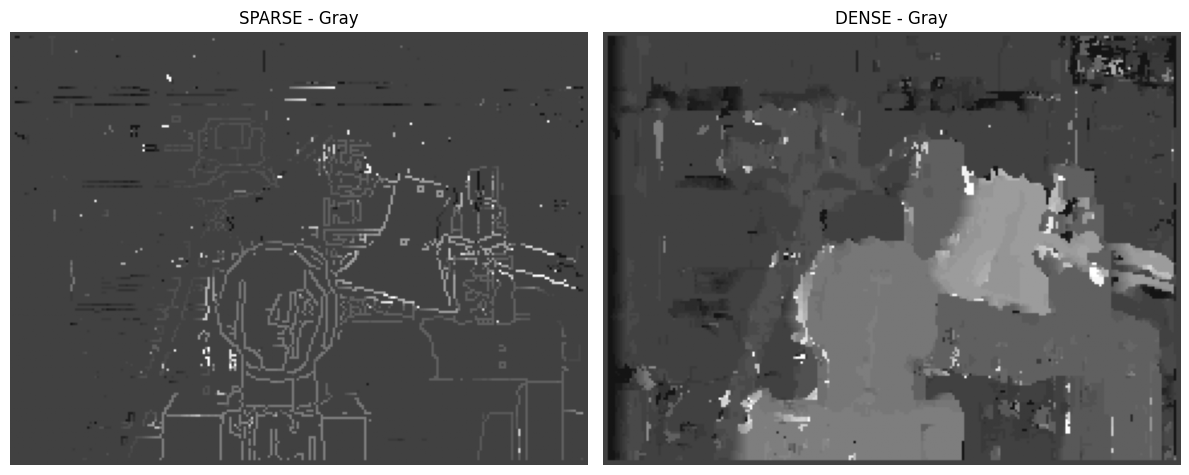

In [38]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1,2,figsize=(12,5))

for ax, nom in zip(axes,["sparse","dense"]):
    gray = cv2.imread(f"/content/ev_{nom}_gray.png",0)
    valid = cv2.imread(f"/content/ev_{nom}_valid.png",0)

    if gray is None or valid is None:
        print("Manquant :",nom)
        continue

    affichage = gray.copy()
    affichage[valid == 0] = 65

    ax.imshow(affichage,cmap="gray",vmin=0,vmax=255)
    ax.set_title(nom.upper()+" - Gray")
    ax.axis("off")

plt.tight_layout()
plt.show()